# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3384 Козьмин Никита Вячеславович. Вариант №8.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Дискретный сигнал - последовательность чисел $x[n]$. Число $n$ обозначает номер отсчёта. Если частота дискретизации равна $f_s$, то отсчёты берутся через $T=1/f_s$ секунд, в моменты $t_n=nT$.

Рассматриваемая система описывается передаточной функцией

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}.$$

При нулевых начальных условиях все входные и выходные отсчёты до $n=0$ равны нулю. Выход вычисляется по разностному уравнению:

$$y[n]=b_0x[n]+b_1x[n-1]+b_2x[n-2]-a_1y[n-1]-a_2y[n-2].$$

Импульсная характеристика $h[n]$ - выход системы при входе $\delta[0]=1$, $\delta[n]=0$ при $n\ne0$. Выход для произвольного входного сигнала можно найти через свёртку с импульсной характеристикой:

$$y[n]=\sum_{m=-\infty}^{\infty}x[m]h[n-m].$$

Нули передаточной функции - корни числителя, полюсы - корни знаменателя. Причинная система устойчива, если все полюсы системы находятся внутри единичной окружности: $|p_i|<1$.

Частотная характеристика получается подстановкой $z=e^{j\hat{\omega}}$. АЧХ равна $|H(e^{j\hat{\omega}})|$, ФЧХ равна $\arg H(e^{j\hat{\omega}})$. Нормированная угловая частота связана с частотой в герцах:

$$\hat{\omega}=2\pi f/f_s.$$

ДПФ и обратное ДПФ для $N$ отсчётов:

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

В Python для ДПФ и обратного ДПФ используются `np.fft.fft` и `np.fft.ifft`. Для периодического сигнала комплексные коэффициенты спектра равны $C[k]=X[k]/N$. В работе строится двусторонний спектр: у косинуса амплитуды $A$ есть две линии высотой $A/2$, на положительной и отрицательной частотах.

Равенство Парсеваля связывает сумму квадратов отсчётов с суммой квадратов модулей ДПФ:

$$\sum_{n=0}^{N-1}|x[n]|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X[k]|^2.$$

## Постановка задачи

В первой части нужно найти импульсную характеристику системы, вычислить выход двумя способами, определить нули и полюсы, проверить устойчивость и построить частотные характеристики.

Во второй части нужно построить сумму двух косинусов, найти ДПФ и спектры этой суммы, выполнить обратное преобразование, восстановить непрерывный сигнал и проверить равенство Парсеваля.

Исходные данные рассчитаны по [таблице вариантов](https://se.moevm.pro/doku.php/courses:digital_signal_processing:prac1:prac1-vars) для варианта 8. Порядок работы соответствует [заданию](https://se.moevm.pro/doku.php/courses:digital_signal_processing:prac1).

| Часть 1 | Значение | Часть 2 | Значение |
|---|---:|---|---:|
| $b_0$ | 0.66 | $N$ | 64 |
| $b_1$ | -0.742236 | $f_s$ | 8000 Гц |
| $b_2$ | 0.924 | $T$ | 0.000125 с |
| $a_0$ | 1 | $A_1$ | 1.08 |
| $a_1$ | 0.9778 | $A_2$ | 2.16 |
| $a_2$ | 0.688 | $f_1$ | 1000 Гц |
| $N_1$ | 28 | $f_2$ | 1500 Гц |
| $N_2$ | 38 | | |
| $f_s$ | 8000 Гц | | |

## Выполнение работы

In [52]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

variant = 8

b0 = 0.5 + 0.02 * variant
b1 = b0 * (-1) ** (variant + 1) * (0.9822 + 0.0178 * variant)
b2 = b0 * (0.8 + 0.2 * (variant % 5))
b = np.array([b0, b1, b2])

a1 = (-1) ** variant * (0.7778 + 0.025 * variant)
a2 = 0.64 + 0.006 * variant
a = np.array([1, a1, a2])

N1 = variant % 10 + 20
N2 = variant % 10 + 30
fs = 1000 * variant

print('b =', b)
print('a =', a)
print('N1 =', N1, ', N2 =', N2, ', fs =', fs, 'Гц')

b = [ 0.66     -0.742236  0.924   ]
a = [1.     0.9778 0.688 ]
N1 = 28 , N2 = 38 , fs = 8000 Гц


### Часть 1. Линейная дискретная система

### 1.1. Импульсная характеристика

На вход подаётся один единичный отсчёт. Выход вычисляется по разностному уравнению. Условия `n >= 1` и `n >= 2` нужны, поскольку отсчёты до начала сигнала равны нулю.

Первые три отсчёта h: [ 0.66       -1.387584    1.82669964]


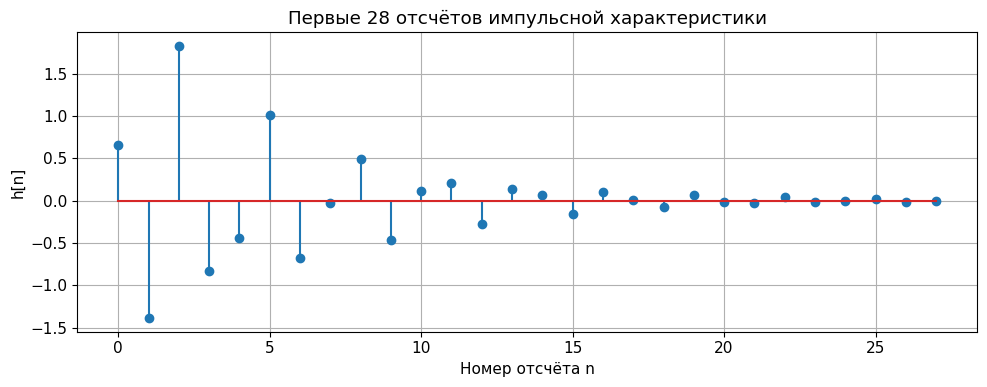

In [53]:
delta = np.zeros(N1)
delta[0] = 1
h = np.zeros(N1)

for n in range(N1):
    h[n] = b[0] * delta[n]
    if n >= 1:
        h[n] += b[1] * delta[n - 1] - a[1] * h[n - 1]
    if n >= 2:
        h[n] += b[2] * delta[n - 2] - a[2] * h[n - 2]

print('Первые три отсчёта h:', h[:3])
plt.stem(np.arange(N1), h)
plt.xlabel('Номер отсчёта n')
plt.ylabel('h[n]')
plt.title('Первые 28 отсчётов импульсной характеристики')
plt.tight_layout()
plt.show()

Для варианта 8:

$$H(z)=\frac{0.66-0.742236z^{-1}+0.924z^{-2}}{1+0.9778z^{-1}+0.688z^{-2}}.$$

Из разностного уравнения при единичном импульсе:

$$h[0]=0.66,\quad h[1]=-1.387584,\quad h[2]=1.8266996352.$$

При $n\ge3$ вход уже не участвует, поэтому $h[n]=-0.9778h[n-1]-0.688h[n-2]$.
Для поиска аналитической формулы используется подстановка $h[n]=p^n$. После сокращения на $p^{n-2}$ получается характеристическое уравнение:

$$p^2+0.9778p+0.688=0.$$

Корни характеристического уравнения:

$$p_{1,2}=\frac{-0.9778\pm\sqrt{0.9778^2-4\cdot0.688}}{2}
\approx-0.4889\pm j0.670057.$$

Эти корни являются полюсами системы. В показательной форме корни записываются как $p_{1,2}=re^{\pm j\theta}$, где

$$r=\sqrt{0.688},\qquad \theta=\arccos\left(\frac{-0.9778}{2r}\right).$$

Аналитическая формула с нулевыми начальными условиями:

$$h[n]=\begin{cases}
0,&n<0,\\
0.66,&n=0,\\
r^{n-1}\left(h[1]\cos((n-1)\theta)+B\sin((n-1)\theta)\right),&n\ge1,
\end{cases}$$

$$B=\frac{h[2]/r-h[1]\cos\theta}{\sin\theta}.$$

Численно $r\approx0.829458$, $\theta\approx0.700644\pi$, $B\approx1.713749$.
На графике видны затухающие колебания. Настоящая длина характеристики бесконечна: система использует предыдущие выходные значения. Число 28 задаёт только длину вычисленного фрагмента.

### 1.2. Реакция по формуле свёртки

Длина массива входа $N_2=38$. Первые 19 отсчётов входа равны единице, остальные 19 - нулю. Значит, ненулевая часть прямоугольного импульса имеет длину 19 отсчётов.

Длина входа: 38
Длина ненулевой части входа: 19
Длина полной свёртки: 65
Длина выбранного фрагмента выхода: 38


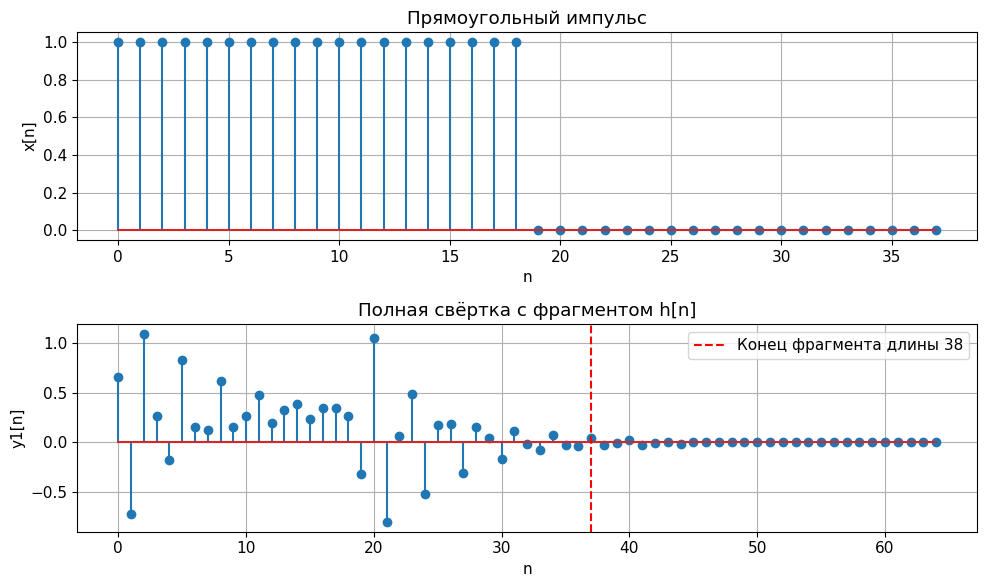

In [54]:
x = np.zeros(N2)
x[:N2 // 2] = 1

y1_full = np.convolve(x, h)
y1 = y1_full[:N2]

print('Длина входа:', len(x))
print('Длина ненулевой части входа:', np.count_nonzero(x))
print('Длина полной свёртки:', len(y1_full))
print('Длина выбранного фрагмента выхода:', len(y1))

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(np.arange(N2), x)
ax[0].set(xlabel='n', ylabel='x[n]', title='Прямоугольный импульс')
ax[1].stem(np.arange(len(y1_full)), y1_full)
ax[1].axvline(N2 - 1, color='red', linestyle='--', label='Конец фрагмента длины 38')
ax[1].set(xlabel='n', ylabel='y1[n]', title='Полная свёртка с фрагментом h[n]')
ax[1].legend()
plt.tight_layout()
plt.show()

Длина свёртки равна $38+28-1=65$ отсчётам. На графике это точки с номерами от 0 до 64. Последние точки нулевые: единицы во входе заканчиваются на отсчёте 18, а массив $h[n]$ - на отсчёте 27. Поэтому после $18+27=45$ свёртка уже равна нулю.

Свёртка ограничивается длиной воздействия, чтобы сравнить вход и выход на одном промежутке времени. Поэтому из 65 отсчётов оставляются первые 38, столько же будет рассчитано по разностному уравнению в пункте 1.3. Выход системы при этом не обрывается на $n=37$: за пределами выбранного участка остаётся затухающий хвост. При использовании полной импульсной характеристики этот хвост теоретически бесконечен.

### 1.3. Реакция по разностному уравнению

Для заданных коэффициентов разностное уравнение имеет вид:

$$y[n]=0.66x[n]-0.742236x[n-1]+0.924x[n-2]-0.9778y[n-1]-0.688y[n-2].$$

Длина воздействия $x[n]$ равна 38 отсчётам: 19 единиц и 19 нулей. Длина рассчитанной реакции $y_2[n]$ тоже равна 38 отсчётам, от $n=0$ до $n=37$. Полная реакция системы бесконечна: после окончания входного импульса выход продолжает колебаться и постепенно затухает. В расчёте показаны только первые 38 отсчётов.

Длины входа и рассчитанного выхода: 38 38
Максимальная разность y1 и y2: 0.011430931392246657


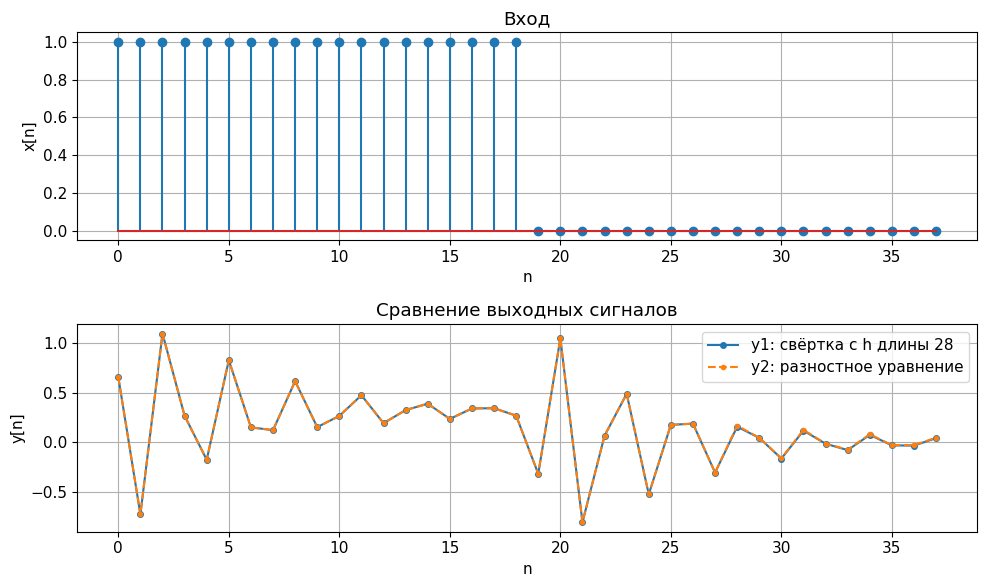

In [55]:
y2 = np.zeros(N2)

for n in range(N2):
    y2[n] = b[0] * x[n]
    if n >= 1:
        y2[n] += b[1] * x[n - 1] - a[1] * y2[n - 1]
    if n >= 2:
        y2[n] += b[2] * x[n - 2] - a[2] * y2[n - 2]

print('Длины входа и рассчитанного выхода:', len(x), len(y2))
print('Максимальная разность y1 и y2:', np.max(np.abs(y1 - y2)))

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(np.arange(N2), x)
ax[0].set(xlabel='n', ylabel='x[n]', title='Вход')
ax[1].plot(y1, 'o-', markersize=4, label='y1: свёртка с h длины 28')
ax[1].plot(y2, '.--', label='y2: разностное уравнение')
ax[1].set(xlabel='n', ylabel='y[n]', title='Сравнение выходных сигналов')
ax[1].legend()
plt.tight_layout()
plt.show()

Графики почти совпали. Самая большая разница - около 0.01143. Разница появилась потому, что для свёртки использованы только первые 28 отсчётов $h[n]$, хотя характеристика бесконечная. На первых 28 отсчётах выходы совпадают с точностью округления.

Для проверки причины разницы $h[n]$ продлена до 38 отсчётов, а свёртка рассчитана повторно. Этого хватит для расчёта первых 38 отсчётов выхода.

In [56]:
h_long = np.zeros(N2)
h_long[:N1] = h
for n in range(N1, N2):
    h_long[n] = -a[1] * h_long[n - 1] - a[2] * h_long[n - 2]

y1_long = np.convolve(x, h_long)[:N2]
print('Разность после продления h:', np.max(np.abs(y1_long - y2)))

Разность после продления h: 4.440892098500626e-16


После продления $h[n]$ результаты совпали с точностью округления. Это подтверждает, что небольшая разница между исходными графиками связана с обрезкой импульсной характеристики.

### 1.4. Нули и полюсы

После умножения числителя и знаменателя $H(z)$ на $z^2$ нули находятся как корни $b_0z^2+b_1z+b_2$, а полюсы - как корни $z^2+a_1z+a_2$. Для расчёта используется `np.roots`.

In [57]:
zeros = np.roots(b)
poles = np.roots(a)

for name, values in [('Нуль', zeros), ('Полюс', poles)]:
    for value in values:
        print(f'{name}: {value.real:.6f} {value.imag:+.6f}j; '
              f'модуль = {abs(value):.6f}; аргумент = {np.angle(value) / np.pi:.6f}π')

Нуль: 0.562300 +1.041066j; модуль = 1.183216; аргумент = 0.342365π
Нуль: 0.562300 -1.041066j; модуль = 1.183216; аргумент = -0.342365π
Полюс: -0.488900 +0.670057j; модуль = 0.829458; аргумент = 0.700644π
Полюс: -0.488900 -0.670057j; модуль = 0.829458; аргумент = -0.700644π


Получены комплексно-сопряжённые пары:

$$z_{1,2}\approx0.562300\pm j1.041066=1.183216e^{\pm j0.342365\pi},$$

$$p_{1,2}\approx-0.488900\pm j0.670057=0.829458e^{\pm j0.700644\pi}.$$

Алгебраическая и показательная формы связаны формулой $q=u+jv=r(\cos\varphi+j\sin\varphi)=re^{j\varphi}$, где $r=\sqrt{u^2+v^2}$, а $\varphi=\arg q$. Модуль задаёт расстояние до начала координат, аргумент - угол на комплексной плоскости. Сопряжённые корни имеют одинаковые модули и противоположные аргументы, поскольку коэффициенты полиномов действительные.

Передаточная функция в виде произведения множителей (значения корней округлены):

$$H(z)\approx0.66\frac{
(z-1.183216e^{j0.342365\pi})(z-1.183216e^{-j0.342365\pi})}{
(z-0.829458e^{j0.700644\pi})(z-0.829458e^{-j0.700644\pi})}.$$

### 1.5. Карта нулей и полюсов

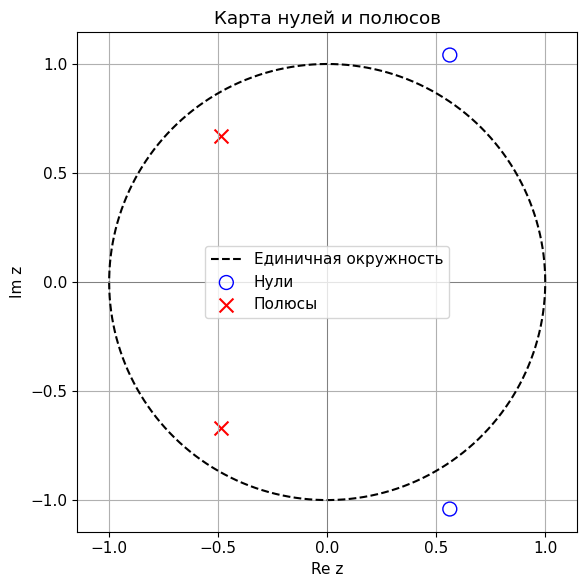

Модули полюсов: [0.82945765 0.82945765]
Система устойчива: True


In [58]:
circle = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(6, 6))
plt.plot(np.cos(circle), np.sin(circle), 'k--', label='Единичная окружность')
plt.scatter(zeros.real, zeros.imag, marker='o', facecolors='none',
            edgecolors='blue', s=100, label='Нули')
plt.scatter(poles.real, poles.imag, marker='x', color='red', s=100, label='Полюсы')
plt.axhline(0, color='gray', linewidth=0.7)
plt.axvline(0, color='gray', linewidth=0.7)
plt.xlabel('Re z')
plt.ylabel('Im z')
plt.title('Карта нулей и полюсов')
plt.axis('equal')
plt.legend()
plt.tight_layout()
plt.show()

print('Модули полюсов:', np.abs(poles))
print('Система устойчива:', np.all(np.abs(poles) < 1))

Оба полюса находятся внутри единичной окружности: модуль каждого полюса примерно 0.82946, меньше 1. Значит, причинная система устойчива. Это согласуется с затуханием импульсной характеристики. Нули находятся снаружи окружности, но устойчивость определяется полюсами. Координаты точек совпадают с числами из пункта 1.4: на карту нанесены именно вычисленные корни.

### 1.6. АЧХ и ФЧХ в нормированных частотах

В передаточную функцию подставляется $z=e^{j\hat{\omega}}$. Тогда $z^{-1}=e^{-j\hat{\omega}}$, а $z^{-2}=e^{-j2\hat{\omega}}$. Для коэффициентов варианта 8 получается:

$$H(e^{j\hat{\omega}})=\frac{0.66-0.742236e^{-j\hat{\omega}}+0.924e^{-j2\hat{\omega}}}{1+0.9778e^{-j\hat{\omega}}+0.688e^{-j2\hat{\omega}}}.$$

На каждой частоте эта формула даёт комплексное число. АЧХ равна модулю этого числа, а ФЧХ - аргументу:

$$A(\hat{\omega})=|H(e^{j\hat{\omega}})|=\sqrt{(\operatorname{Re}H)^2+(\operatorname{Im}H)^2},\qquad
\varphi(\hat{\omega})=\arg H(e^{j\hat{\omega}}).$$

Например, при $\hat{\omega}=\pi/2$ (2000 Гц) значения экспонент равны $e^{-j\pi/2}=-j$ и $e^{-j\pi}=-1$. После подстановки:

$$H(e^{j\pi/2})=\frac{0.66+0.742236j-0.924}{1-0.9778j-0.688}
=\frac{-0.264+0.742236j}{0.312-0.9778j}
\approx-0.767133-0.025214j.$$

Отсюда значения АЧХ и ФЧХ на этой частоте:

$$A(\pi/2)\approx\sqrt{(-0.767133)^2+(-0.025214)^2}\approx0.767547,$$

$$\varphi(\pi/2)\approx-3.108736\approx-0.989542\pi.$$

Значит, колебание частоты 2000 Гц в установившемся режиме имеет на выходе примерно 76.8% входной амплитуды и сдвиг фазы около $-0.990\pi$.

В коде `q = np.exp(-1j * omega)` соответствует $z^{-1}$, а `q ** 2` - $z^{-2}$. Значения `H` рассчитываются для 8193 частот от 0 до $\pi$, затем `np.abs(H)` даёт АЧХ, а `np.angle(H)` - ФЧХ. На графиках частота и фаза поделены на $\pi$ для удобства чтения.

Основная полоса нормированных угловых частот - $[-\pi;\pi)$. Из-за симметрии характеристик системы с действительными коэффициентами на графиках показана положительная половина $[0;\pi]$.

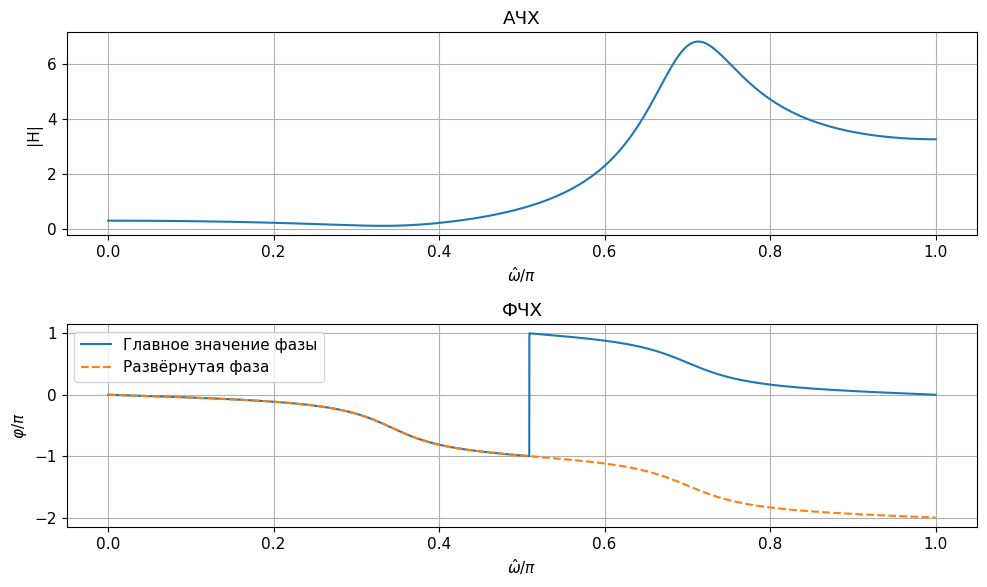

Минимум: |H| = 0.127034, частота = 0.332642π
Максимум: |H| = 6.830279, частота = 0.713135π
|H(0)| = 0.315764; |H(π)| = 3.275466
Переход фазы от -π к +π: частота ≈ 0.5089π, |H| ≈ 0.8454


In [59]:
omega = np.linspace(0, np.pi, 8193)
q = np.exp(-1j * omega)
H = (b[0] + b[1] * q + b[2] * q ** 2) / (1 + a[1] * q + a[2] * q ** 2)
magnitude = np.abs(H)
phase = np.angle(H)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(omega / np.pi, magnitude)
ax[0].set(xlabel=r'$\hat{\omega}/\pi$', ylabel='|H|', title='АЧХ')
ax[1].plot(omega / np.pi, phase / np.pi, label='Главное значение фазы')
ax[1].plot(omega / np.pi, np.unwrap(phase) / np.pi, '--', label='Развёрнутая фаза')
ax[1].set(xlabel=r'$\hat{\omega}/\pi$', ylabel=r'$\varphi/\pi$', title='ФЧХ')
ax[1].legend()
plt.tight_layout()
plt.show()

i_min = np.argmin(magnitude)
i_max = np.argmax(magnitude)
print(f'Минимум: |H| = {magnitude[i_min]:.6f}, частота = {omega[i_min] / np.pi:.6f}π')
print(f'Максимум: |H| = {magnitude[i_max]:.6f}, частота = {omega[i_max] / np.pi:.6f}π')
print(f'|H(0)| = {magnitude[0]:.6f}; |H(π)| = {magnitude[-1]:.6f}')

jumps = np.where(np.abs(np.diff(phase)) > np.pi)[0]
for index in jumps:
    print(f'Переход фазы от -π к +π: частота ≈ {omega[index] / np.pi:.4f}π, '
          f'|H| ≈ {magnitude[index]:.4f}')

Минимум АЧХ находится около $0.333\pi$, близко к аргументу нуля $0.342\pi$. Максимум - около $0.713\pi$, близко к аргументу полюса $0.701\pi$. На единичной окружности близость к нулю уменьшает модуль числителя, а близость к полюсу уменьшает модуль знаменателя. Поэтому положения нулей и полюсов объясняют провал и подъём АЧХ. Частоты экстремумов не обязаны точно совпадать с аргументами корней: влияют все множители функции.

АЧХ не обращается в ноль: минимум АЧХ примерно 0.127. Поэтому скачка фазы на $\pi$, связанного с прохождением через нуль АЧХ, здесь нет. На графике главного значения фазы есть переход от $-\pi$ к $+\pi$, то есть на $2\pi$, около $0.509\pi$, при $|H|\approx0.845$. Переход возникает из-за представления фазы в диапазоне $[-\pi;\pi]$ и исчезает после `np.unwrap`.

Низкие частоты подавляются сильнее высоких: например, на нулевой частоте коэффициент передачи около 0.316, на частоте $\pi$ - около 3.275. В верхней части полосы также есть выраженный максимум. Это согласуется с колебаниями на фронтах выходного прямоугольного импульса.

### 1.7. АЧХ и ФЧХ в герцах

При $f_s=8000$ Гц основная полоса равна $[-4000;4000)$ Гц. На графике показана положительная половина полосы: от 0 до 4000 Гц.

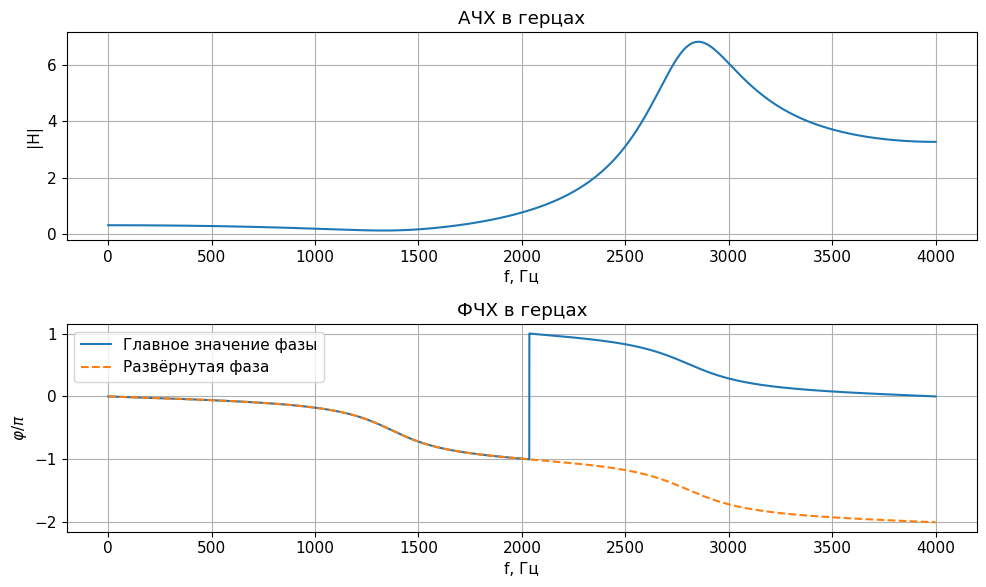

Частота минимума: 1330.57 Гц
Частота максимума: 2852.54 Гц


In [60]:
frequency = omega * fs / (2 * np.pi)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(frequency, magnitude)
ax[0].set(xlabel='f, Гц', ylabel='|H|', title='АЧХ в герцах')
ax[1].plot(frequency, phase / np.pi, label='Главное значение фазы')
ax[1].plot(frequency, np.unwrap(phase) / np.pi, '--', label='Развёрнутая фаза')
ax[1].set(xlabel='f, Гц', ylabel=r'$\varphi/\pi$', title='ФЧХ в герцах')
ax[1].legend()
plt.tight_layout()
plt.show()

print(f'Частота минимума: {frequency[i_min]:.2f} Гц')
print(f'Частота максимума: {frequency[i_max]:.2f} Гц')

Формы графиков не изменились: заменена только горизонтальная шкала. Соответствие задаётся формулой $f=\hat{\omega}f_s/(2\pi)$. Например, $0.5\pi$ соответствует 2000 Гц, а $\pi$ - 4000 Гц. Минимум находится около 1330 Гц, максимум - около 2853 Гц.

### Часть 2. Дискретное преобразование Фурье

### 2.1. Исходная последовательность

По варианту $N=64$, $f_s=8000$ Гц, $T=0.000125$ с, $A_1=1.08$, $A_2=2.16$, $f_1=1000$ Гц, $f_2=1500$ Гц.

$$x[n]=1.08\cos(2\pi\cdot1000nT+\pi/4)+2.16\cos(2\pi\cdot1500nT+\pi/8).$$

Показаны 64 отсчёта в шкале времени $nT$ и нормированного времени $n=t/T$.

N = 64 , fs = 8000 Гц, T = 0.000125 с
A1 = 1.08 , A2 = 2.16 , f1 = 1000.0 Гц, f2 = 1500.0 Гц
Число периодов гармоник в 64 отсчётах: 8.0 12.0


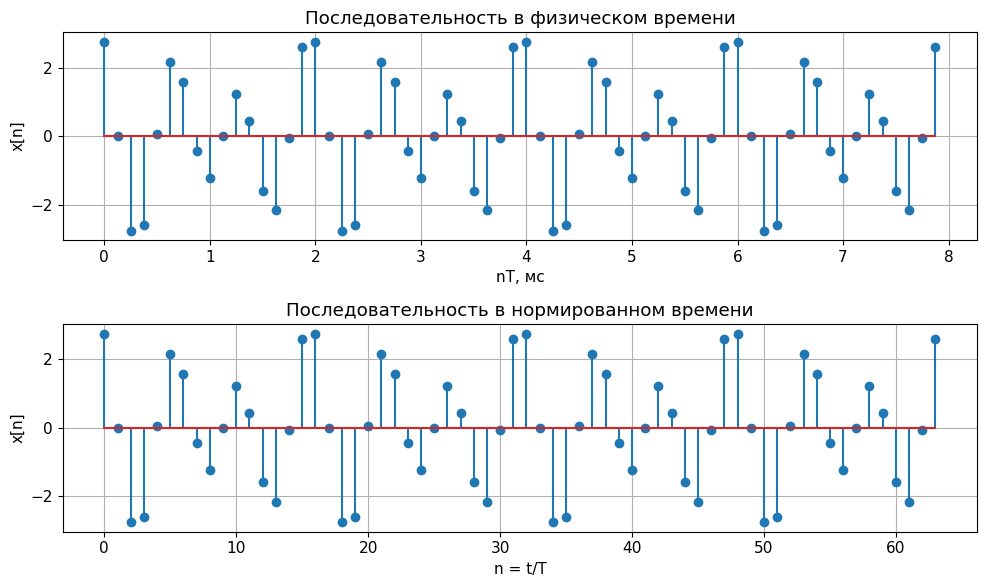

In [61]:
N = 64
fs2 = 2000 * (variant % 5 + 1)
T = 1 / fs2
A1 = 1 + 0.01 * variant
A2 = 2 * A1
f1 = fs2 / 8
f2 = 1.5 * f1

n2 = np.arange(N)
t_samples = n2 * T
x2 = A1 * np.cos(2 * np.pi * f1 * t_samples + np.pi / 4) + \
     A2 * np.cos(2 * np.pi * f2 * t_samples + np.pi / 8)

print('N =', N, ', fs =', fs2, 'Гц, T =', T, 'с')
print('A1 =', A1, ', A2 =', A2, ', f1 =', f1, 'Гц, f2 =', f2, 'Гц')
print('Число периодов гармоник в 64 отсчётах:', f1 * N * T, f2 * N * T)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(t_samples * 1000, x2)
ax[0].set(xlabel='nT, мс', ylabel='x[n]', title='Последовательность в физическом времени')
ax[1].stem(n2, x2)
ax[1].set(xlabel='n = t/T', ylabel='x[n]', title='Последовательность в нормированном времени')
plt.tight_layout()
plt.show()

Один шаг по $n$ соответствует $T=0.125$ мс. Значения сигнала на обоих графиках одинаковые, различаются только единицы времени.

В 64 отсчёта укладываются 8 периодов первой гармоники и 12 периодов второй. Поэтому блок из 64 отсчётов можно периодически повторять без разрыва. Длительность блока $NT=8$ мс, а последний отсчёт расположен в момент $(N-1)T=7.875$ мс. Минимальный период суммы равен 16 отсчётам (2 мс); 64 отсчёта содержат четыре таких периода.

### 2.2. ДПФ и обратное ДПФ

Для 64 отсчётов сигнала из пункта 2.1 рассчитывается ДПФ:

$$X[k]=\sum_{n=0}^{63}x[n]e^{-j2\pi kn/64},\qquad k=0,1,\ldots,63.$$

Здесь $n$ - номер отсчёта времени, а $k$ - номер частоты в спектре. Для каждого $k$ отсчёты сигнала умножаются на значения комплексного колебания $e^{-j2\pi kn/64}$, затем результаты складываются. Полученное комплексное число $X[k]$ содержит информацию об амплитуде и фазе этой частотной составляющей.

Шаг частоты равен $f_s/N=8000/64=125$ Гц. Поэтому частоты 1000 и 1500 Гц соответствуют индексам $k=8$ и $k=12$.

Чтобы понять значения ДПФ, достаточно представить каждый косинус через две комплексные экспоненты:

$$\cos\alpha=\frac{e^{j\alpha}+e^{-j\alpha}}{2}.$$

Например, при $k=8$ множитель $e^{-j2\pi8n/64}$ убирает зависимость от $n$ у положительной частотной составляющей первого косинуса. Остаётся $1.08e^{j\pi/4}/2$. Сумма 64 одинаковых значений даёт:

$$X[8]=64\cdot\frac{1.08}{2}e^{j\pi/4}=34.56e^{j\pi/4}.$$

Остальные составляющие в этой сумме взаимно сокращаются, поскольку содержат целое число периодов. Аналогично получаются четыре ненулевых коэффициента ДПФ:

$$X[8]=34.56e^{j\pi/4},\qquad X[56]=34.56e^{-j\pi/4},$$

$$X[12]=69.12e^{j\pi/8},\qquad X[52]=69.12e^{-j\pi/8}.$$

Индексы 56 и 52 соответствуют отрицательным частотам: $56-64=-8$ и $52-64=-12$. Остальные коэффициенты теоретически равны нулю, а при вычислении могут содержать маленькие остатки из-за округления.

Обратное ДПФ (ОДПФ) собирает отсчёты сигнала из этих коэффициентов:

$$x_{back}[n]=\frac{1}{64}\sum_{k=0}^{63}X[k]e^{j2\pi kn/64}.$$

По сравнению с ДПФ знак в экспоненте меняется на плюс и появляется деление на 64. Сопряжённые коэффициенты складываются попарно и дают действительные косинусы. После подстановки четырёх ненулевых коэффициентов:

$$x_{back}[n]=\frac{2\cdot34.56}{64}\cos(2\pi\cdot8n/64+\pi/4)
+\frac{2\cdot69.12}{64}\cos(2\pi\cdot12n/64+\pi/8).$$

Коэффициенты перед косинусами равны $2\cdot34.56/64=1.08$ и $2\cdot69.12/64=2.16$, поэтому получается исходная последовательность $x[n]$.

В коде `np.fft.fft(x2)` вычисляет ДПФ быстрым алгоритмом, а `np.fft.ifft(X)` - ОДПФ. Деление на $N=64$ уже выполняется внутри `ifft`.

Ошибка восстановления: 9.155133597044475e-16
Максимальная мнимая часть: 2.5554371601195523e-16


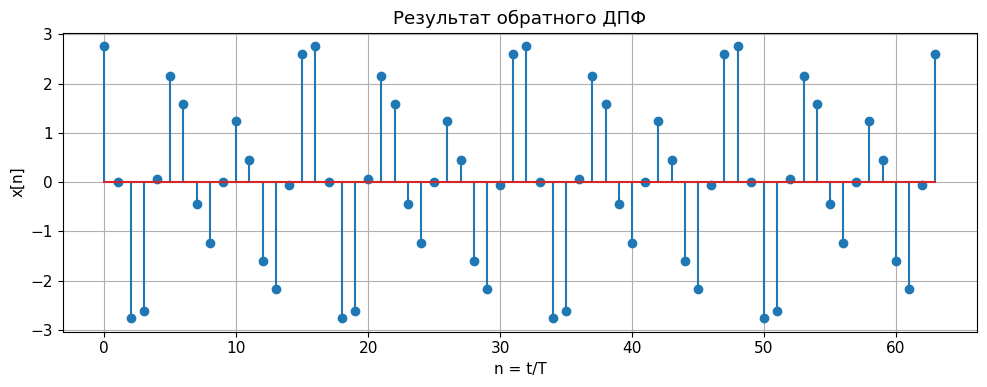

In [62]:
X = np.fft.fft(x2)
x_back = np.fft.ifft(X)

print('Ошибка восстановления:', np.max(np.abs(x_back - x2)))
print('Максимальная мнимая часть:', np.max(np.abs(x_back.imag)))

plt.stem(n2, x_back.real)
plt.xlabel('n = t/T')
plt.ylabel('x[n]')
plt.title('Результат обратного ДПФ')
plt.tight_layout()
plt.show()

Обратное ДПФ восстановило исходные отсчёты с погрешностью порядка $10^{-15}$. Маленькая мнимая часть связана с округлением при вычислениях; исходный сигнал действительный.

### 2.3. Амплитудный и фазовый спектры

Дискретное время задаётся моментами $t_n=nT$, а нормированное время равно $t_n/T=n$. Поэтому шаг 1 по нормированному времени соответствует $T=0.125$ мс.

С помощью `fftshift` отрицательные частоты перенесены в левую половину графика. Теперь номера гармоник идут от $-32$ до 31. Нормированные частоты и частоты в герцах связаны так:

$$\hat{\omega}_k=\frac{2\pi k}{N},\qquad f_k=\frac{kf_s}{N}=\frac{\hat{\omega}_kf_s}{2\pi}.$$

Например, 1000 Гц соответствуют $k=8$ и $\hat{\omega}=0.25\pi$, а 1500 Гц - $k=12$ и $\hat{\omega}=0.375\pi$.

Амплитуды двустороннего спектра равны $|X[k]|/N$. Фаза показана только у ненулевых линий: у нулевой комплексной величины фаза не определена, а очень маленькие вычислительные остатки не несут полезной информации.

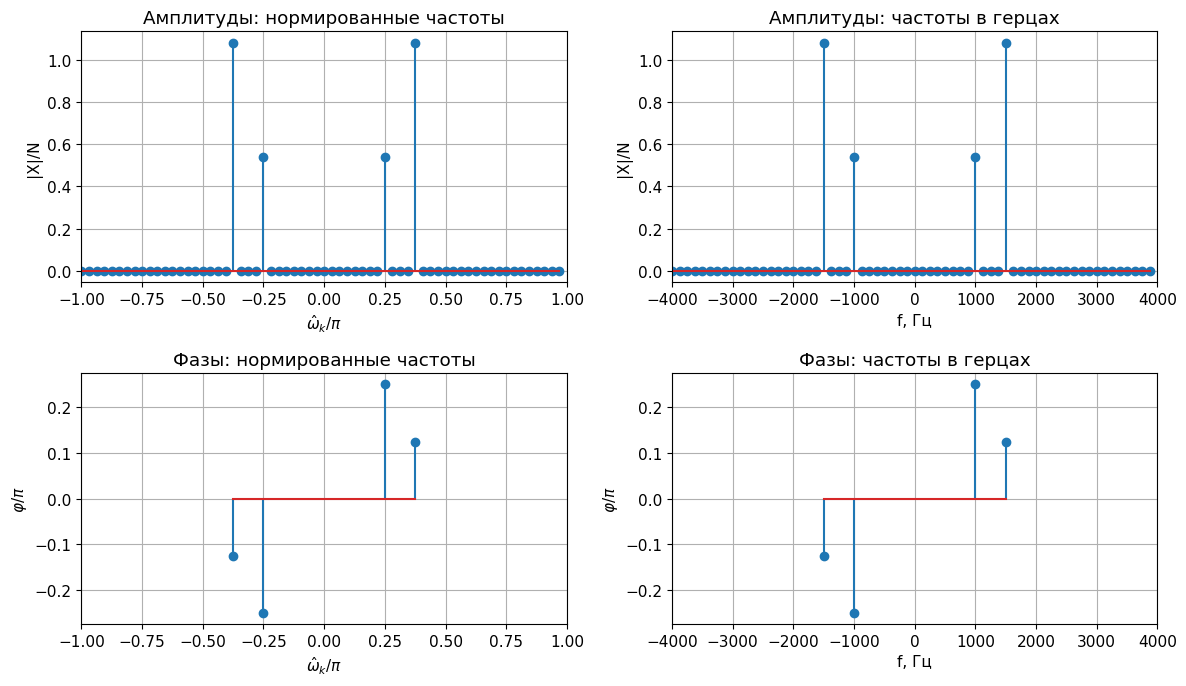

 k      f, Гц     ω/π     амплитуда     фаза/π
-12    -1500.0   -0.375       1.080      -0.125
 -8    -1000.0   -0.250       0.540      -0.250
  8     1000.0    0.250       0.540       0.250
 12     1500.0    0.375       1.080       0.125


In [63]:
k = np.arange(-N // 2, N // 2)
X_center = np.fft.fftshift(X)
omega_k = 2 * np.pi * k / N
f_k = k * fs2 / N
amplitude = np.abs(X_center) / N
spectrum_phase = np.angle(X_center)
mask = amplitude > 1e-10

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].stem(omega_k / np.pi, amplitude)
ax[0, 0].set(xlabel=r'$\hat{\omega}_k/\pi$', ylabel='|X|/N', title='Амплитуды: нормированные частоты')
ax[1, 0].stem(omega_k[mask] / np.pi, spectrum_phase[mask] / np.pi)
ax[1, 0].set(xlabel=r'$\hat{\omega}_k/\pi$', ylabel=r'$\varphi/\pi$', title='Фазы: нормированные частоты')
ax[0, 1].stem(f_k, amplitude)
ax[0, 1].set(xlabel='f, Гц', ylabel='|X|/N', title='Амплитуды: частоты в герцах')
ax[1, 1].stem(f_k[mask], spectrum_phase[mask] / np.pi)
ax[1, 1].set(xlabel='f, Гц', ylabel=r'$\varphi/\pi$', title='Фазы: частоты в герцах')
for row in range(2):
    ax[row, 0].set_xlim(-1, 1)
    ax[row, 1].set_xlim(-fs2 / 2, fs2 / 2)
plt.tight_layout()
plt.show()

print(' k      f, Гц     ω/π     амплитуда     фаза/π')
for i in np.where(mask)[0]:
    print(f'{k[i]:3d}  {f_k[i]:9.1f}  {omega_k[i] / np.pi:7.3f}  '
          f'{amplitude[i]:10.3f}  {spectrum_phase[i] / np.pi:10.3f}')

| $k$ | $f$, Гц | $\hat{\omega}/\pi$ | $\lvert X[k]\rvert/N$ | Фаза |
|---:|---:|---:|---:|---:|
| -12 | -1500 | -0.375 | 1.08 | $-\pi/8$ |
| -8 | -1000 | -0.25 | 0.54 | $-\pi/4$ |
| 8 | 1000 | 0.25 | 0.54 | $\pi/4$ |
| 12 | 1500 | 0.375 | 1.08 | $\pi/8$ |

Для каждого косинуса получились две спектральные линии с половиной амплитуды косинуса. Амплитудный спектр симметричен, а фазы на противоположных частотах имеют противоположные знаки.

Обе заданные частоты точно попали в частотную сетку ДПФ, поэтому заметных линий всего четыре; остальные значения отличаются от нуля только из-за округления.

### 2.4. Конечная и периодическая последовательности

ДПФ блока из 64 отсчётов имеет одинаковые значения для конечной последовательности и для одного периода бесконечной периодической последовательности. Но коэффициенты спектра периодического сигнала нужно разделить на $N$.

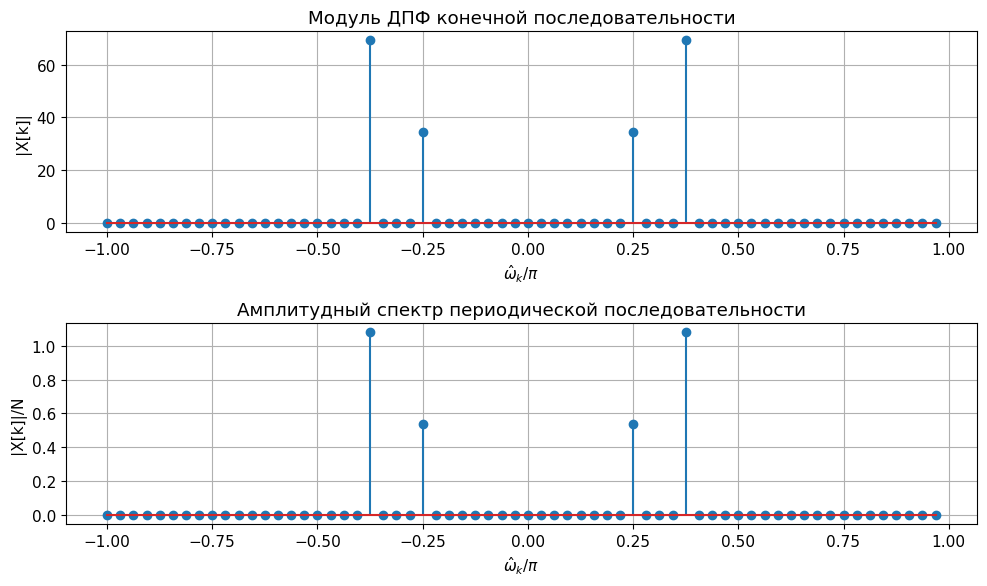

Модули ненулевых отсчётов ДПФ: [69.12 34.56 34.56 69.12]
Амплитуды периодического спектра: [1.08 0.54 0.54 1.08]


In [64]:
X_finite = np.fft.fft(x2)
finite_magnitude = np.abs(np.fft.fftshift(X_finite))

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(omega_k / np.pi, finite_magnitude)
ax[0].set(xlabel=r'$\hat{\omega}_k/\pi$', ylabel='|X[k]|', title='Модуль ДПФ конечной последовательности')
ax[1].stem(omega_k / np.pi, amplitude)
ax[1].set(xlabel=r'$\hat{\omega}_k/\pi$', ylabel='|X[k]|/N', title='Амплитудный спектр периодической последовательности')
plt.tight_layout()
plt.show()

print('Модули ненулевых отсчётов ДПФ:', finite_magnitude[mask])
print('Амплитуды периодического спектра:', amplitude[mask])

Частоты линий совпадают. Модули ДПФ равны 34.56 и 69.12, а соответствующие амплитуды периодического спектра - 0.54 и 1.08. Отношение равно $N=64$.

Для конечного сигнала показаны только значения преобразования на сетке ДПФ. Между этими частотами преобразование конечного фрагмента не обязано быть нулевым. У периодического сигнала спектр состоит из отдельных линий.

### 2.5. Восстановление аналогового сигнала

Для восстановления используется формула из задания:

$$x(t)=\frac{1}{N}\sum_{k=-N/2}^{N/2-1}X_a[k]e^{j2\pi kt/(NT)}.$$

Массив `X_center` получается с помощью `fftshift` и содержит $X_a[k]$ в порядке от $k=-32$ до $k=31$. Это соответствует перестановке из задания:

$$X_a[k]=\begin{cases}
X[N+k],&-N/2\leq k\leq-1,\\
X[k],&0\leq k\leq N/2-1.
\end{cases}$$

Значения рассчитываются на отрезке $[0;(N-1)T]$ с шагом $T/4=0.00003125$ с. Последний момент времени равен $(N-1)T=0.007875$ с. Отрицательные частоты нужны, чтобы восстановить сигнал между отсчётами корректно.

Шаг времени: 3.125e-05 с
Интервал: 0.0 ... 0.007875 с
Ошибка между восстановленным и исходным сигналами: 3.019806626980426e-14
Ошибка в исходных отсчётах: 2.0719537197066984e-14


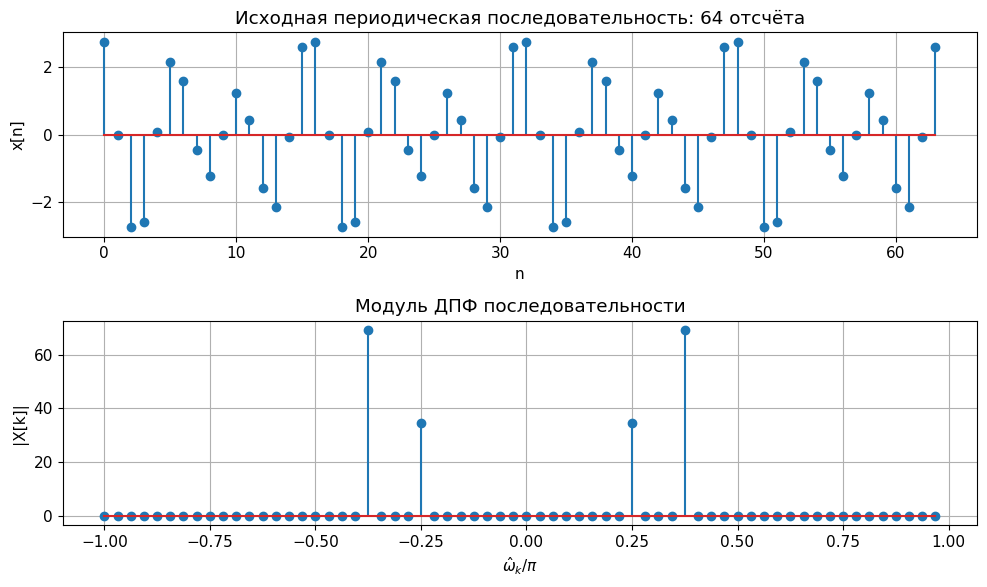

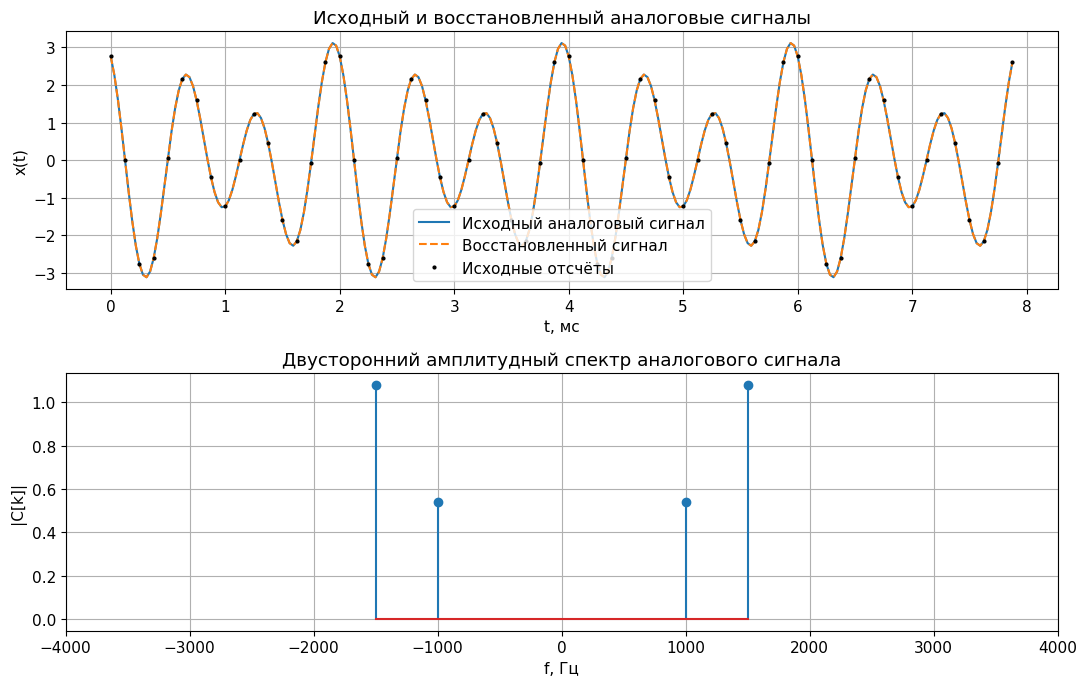

In [65]:
# 4 шага на один интервал между соседними отсчётами.
t_dense = np.arange(4 * (N - 1) + 1) * T / 4
x_restored_complex = np.zeros(len(t_dense), dtype=complex)

for i in range(N):
    x_restored_complex += X_center[i] * np.exp(1j * 2 * np.pi * k[i] * t_dense / (N * T)) / N

x_restored = x_restored_complex.real
x_original = A1 * np.cos(2 * np.pi * f1 * t_dense + np.pi / 4) + \
             A2 * np.cos(2 * np.pi * f2 * t_dense + np.pi / 8)

print('Шаг времени:', T / 4, 'с')
print('Интервал:', t_dense[0], '...', t_dense[-1], 'с')
print('Ошибка между восстановленным и исходным сигналами:', np.max(np.abs(x_restored - x_original)))
print('Ошибка в исходных отсчётах:', np.max(np.abs(x_restored[::4] - x2)))

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(n2, x2)
ax[0].set(xlabel='n', ylabel='x[n]', title='Исходная периодическая последовательность: 64 отсчёта')
ax[1].stem(omega_k / np.pi, np.abs(X_center))
ax[1].set(xlabel=r'$\hat{\omega}_k/\pi$', ylabel='|X[k]|', title='Модуль ДПФ последовательности')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(t_dense * 1000, x_original, label='Исходный аналоговый сигнал')
ax[0].plot(t_dense * 1000, x_restored, '--', label='Восстановленный сигнал')
ax[0].plot(t_samples * 1000, x2, '.', color='black', markersize=4, label='Исходные отсчёты')
ax[0].set(xlabel='t, мс', ylabel='x(t)', title='Исходный и восстановленный аналоговые сигналы')
ax[0].legend()
ax[1].stem(f_k[mask], amplitude[mask])
ax[1].set(xlabel='f, Гц', ylabel='|C[k]|', title='Двусторонний амплитудный спектр аналогового сигнала')
ax[1].set_xlim(-fs2 / 2, fs2 / 2)
plt.tight_layout()
plt.show()

### 2.6. Объяснение восстановления

Аналоговый периодический сигнал состоит из гармоник с частотами $f_k=k/(NT)$. Комплексные коэффициенты гармоник равны $C[k]=X_a[k]/N$. Поэтому модуль ДПФ нужно разделить на 64, чтобы получить высоты линий двустороннего амплитудного спектра аналогового сигнала. Например, $34.56/64=0.54$, а амплитуда соответствующего косинуса равна $2\cdot0.54=1.08$.

Графики исходного и восстановленного сигналов совпадают с точностью округления. Частоты 1000 и 1500 Гц меньше частоты Найквиста $f_s/2=4000$ Гц, а в выбранный блок укладывается целое число периодов. Поэтому в этой задаче восстановление по ДПФ даёт исходную сумму косинусов и между отсчётами.

### 2.7. Равенство Парсеваля

In [66]:
energy_time = np.sum(np.abs(x2) ** 2)
energy_frequency = np.sum(np.abs(X) ** 2) / N

print(f'Сумма квадратов во времени: {energy_time:.12f}')
print(f'Сумма квадратов в частотах:  {energy_frequency:.12f}')
print('Разность:', abs(energy_time - energy_frequency))
print('Равенство выполнено:', np.isclose(energy_time, energy_frequency))
print('Средний квадрат сигнала:', energy_time / N)

Сумма квадратов во времени: 186.624000000000
Сумма квадратов в частотах:  186.624000000000
Разность: 0.0
Равенство выполнено: True
Средний квадрат сигнала: 2.916


Обе суммы равны 186.624 с точностью округления. ДПФ перераспределяет информацию по частотам, сохраняя сумму квадратов с учётом множителя $1/N$.

Здесь это энергия выбранного блока из 64 отсчётов. У бесконечного ненулевого периодического сигнала полная энергия бесконечна. Поэтому удобнее использовать средний квадрат (среднюю мощность). Средний квадрат равен $186.624/64=2.916$, что также совпадает с $(A_1^2+A_2^2)/2$.

## Выводы

В первой части была исследована рекурсивная система второго порядка. Полюсы системы имеют модуль 0.82946, поэтому система устойчива, а импульсная характеристика затухает. Характеристика бесконечна, хотя по заданию рассчитаны первые 28 отсчётов. Выходы, найденные свёрткой и по разностному уравнению, совпадают при достаточной длине используемого фрагмента характеристики. Низкие частоты система подавляет сильнее высоких; максимум АЧХ находится около 2853 Гц.

Во второй части были найдены ДПФ и спектры суммы двух косинусов. Спектральные линии расположены на частотах $\pm1000$ и $\pm1500$ Гц. Обратное ДПФ восстановило исходные отсчёты, а сумма гармоник по коэффициентам ДПФ - исходный аналоговый сигнал на более частой временной сетке. Равенство Парсеваля выполнено: обе суммы равны 186.624. Различия при проверках объясняются округлением чисел.